In [1]:
import openmc
import numpy as np
import math
import pathlib

In [2]:
# Material Definition
p = 'wo'
m1 = openmc.Material()
m1.add_element('H',1.0,p)
m1.set_density('g/cc',1.0)

m2 = openmc.Material()
m2.add_element('Pb',1.0,p)
m2.set_density('g/cc',11.348)

materials = openmc.Materials([m1,m2])

Cells 1 and 2 contain identical fast neutron sources at their centers; they are also filled with lead which will interact strongly with the fast neutrons to produce many gammas. c3 and the detector cell are filled with elemental hydrogen which does not strongly attenuate these gammas.

In [3]:
# Surface Specification
s1 = openmc.Sphere(x0=-3,r=1)
s2 = openmc.Sphere(x0=3, r=1)
s3 = openmc.Sphere(x0=0, r=0.5)
s4 = openmc.Sphere(r=5,boundary_type='vacuum')

# Cell specification
c1 = openmc.Cell(fill=m2,region=-s1)
c2 = openmc.Cell(fill=m2,region=-s2)
detector = openmc.Cell(fill=m1,region=-s3)
c3 = openmc.Cell(fill=m1,region=(+s1&+s2&+s3&-s4))
c4 = openmc.Cell(fill=None,region=+s4)

geometry = openmc.Geometry([c1,c2, detector, c3,c4])

In [4]:
# Tally specification
f5 = openmc.Tally()
f5.filters = []
f5.filters.append(openmc.CellBornFilter([c1,c2]))
f5.filters.append(openmc.ParticleFilter('photon'))

f5.scores = ['flux']

tallies = openmc.Tallies(tallies=[f5]) 

In [5]:
settings = openmc.Settings()
settings.run_mode='fixed source'

# Source specification
def create_source(x=0,y=0,z=0):
    source = openmc.IndependentSource()
    source.space = openmc.stats.Point((x,y,z))
    source.angle = openmc.stats.Isotropic() 
    source.particle = 'neutron'
    source.energy = openmc.stats.delta_function(2e6) # energy in eV 

    return source

# Enable photon transport
settings.photon_transport = True 

# fluorescence photons and auger electrons enabled
settings.atomic_relaxation = True 

sources = [create_source(i,0,0) for i in [-3,3]]
settings.source = sources
settings.uniform_source_sampling = True

# History settings
settings.particles = 100
settings.batches = 100

In [6]:
model = openmc.model.Model(geometry, materials, settings, tallies)

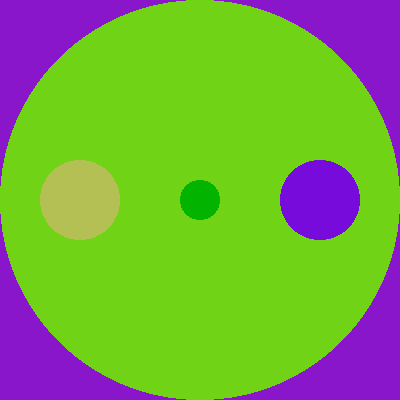

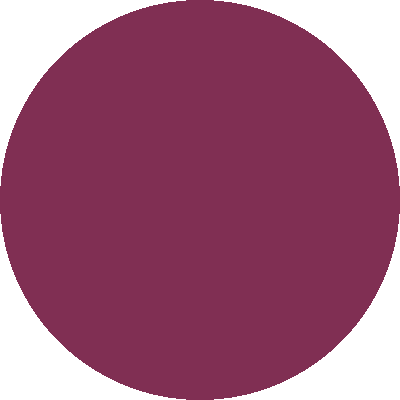

In [7]:
plots = openmc.Plots()
w = 10
origin = (0,0,0)

plot = openmc.SlicePlot()
plot.basis = 'xz'
plot.origin = origin
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'yz'
plot.origin = origin
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'material'
plots.append(plot)
openmc.plot_inline(plots)

In [8]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [9]:
with openmc.StatePoint(sp_filename) as sp:
    for key in (sp.tallies.keys()):
        print(sp.tallies)
        tally_name = sp.tallies[key].name

        results = sp.get_tally(name=tally_name)
        df = results.get_pandas_dataframe()
        print(df)
        print(f"{tally_name} = {df['mean'].sum()} +/- {df['std. dev.'].sum()}\n")


{np.int32(1): Tally
	ID             =	1
	Name           =	
	Filters        =	CellBornFilter, ParticleFilter
	Nuclides       =	total
	Scores         =	['flux']
	Estimator      =	tracklength
	Multiply dens. =	True}
   cellborn particle nuclide score     mean  std. dev.
0         1   photon   total  flux 1.33e-01   1.20e-02
1         2   photon   total  flux 1.24e-01   1.27e-02
 = 0.25683142203780923 +/- 0.024620309503210223



Given that the geometry is symmetric, the photon contributions from c1 and c2 should be equal; the issue is that the source sites may not have been sampled evenly. In the limit of many particle histories, the contributions from each cell will equilibrate because 

In [10]:
def create_model(particles,batches):
    model_base = model # defined previously
    model_base.settings._particles = particles
    model_base.settings._batches = batches
    return model_base

In [11]:
for no_particles in np.logspace(2,5,4,base=10):
    new_model = create_model(no_particles,100)

    sp_filename = new_model.run(output=False);
    
    with openmc.StatePoint(sp_filename) as sp:
        for key in (sp.tallies.keys()):
            tally_name = sp.tallies[key].name
    
            results = sp.get_tally(name=tally_name)
            df = results.get_pandas_dataframe()
            c1_res = df[df['cellborn']==1]
            c2_res = df[df['cellborn']==2]

            # sample means
            res_1 = (c1_res['mean'].squeeze())
            res_1s = (c1_res['std. dev.'].squeeze())
            res_2 = (c2_res['mean'].squeeze())
            res_2s = (c2_res['std. dev.'].squeeze())

            print(f"\n--------------------\nno_particles={no_particles}")
            print(df)
            print(f"flux contributions difference = {abs(res_1 -res_2)} +/- {res_1s + res_2s}")
            print(f"--------------------")
            


--------------------
no_particles=100.0
   cellborn particle nuclide score     mean  std. dev.
0         1   photon   total  flux 1.33e-01   1.20e-02
1         2   photon   total  flux 1.24e-01   1.27e-02
flux contributions difference = 0.00945034413638017 +/- 0.024620309503210227
--------------------

--------------------
no_particles=1000.0
   cellborn particle nuclide score     mean  std. dev.
0         1   photon   total  flux 1.32e-01   3.78e-03
1         2   photon   total  flux 1.38e-01   4.74e-03
flux contributions difference = 0.006838505089074964 +/- 0.008517892691721974
--------------------

--------------------
no_particles=10000.0
   cellborn particle nuclide score     mean  std. dev.
0         1   photon   total  flux 1.39e-01   1.24e-03
1         2   photon   total  flux 1.36e-01   1.31e-03
flux contributions difference = 0.0025373815459312776 +/- 0.002544724434465512
--------------------

--------------------
no_particles=100000.0
   cellborn particle nuclide score    